<a href="https://colab.research.google.com/github/Baelfyre/Magic_Lotto/blob/explore%2Fkmeans-642-descriptive/notebooks/lotto_phase7_kmeans_descriptive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 7: Lotto 6/42 K-means descriptive exploration

**No predictive claims.** The existing `STOP_NO_REPRODUCIBLE_PREDICTIVE_SIGNAL` verdict remains unchanged. Historical 6/42 combinations are unordered sets. This notebook runs only on the Phase 4 training partition (902 records through November 12, 2022); the validation and locked test draws are not opened.

Run the first code cell to initialize the notebook. It discovers the repository root from the current directory or its parents; in Colab, it clones the default branch only when no usable checkout is present. It installs the Phase 7 requirements into the active kernel and validates imports before analysis. Re-running it reuses the checkout without resetting files. Local Jupyter uses the same cell and does not clone.


In [1]:
# codebase_provenance_JEO
from pathlib import Path
import json
import os
import subprocess
import sys

required_files = ('scripts/phase7_kmeans_642.py', 'requirements-phase7.txt', 'lotto_6_42_cleaned_normalized.csv')
def is_repo_root(path):
    return all((path / name).is_file() for name in required_files)

repo_root = next((path for path in (Path.cwd(), *Path.cwd().parents) if is_repo_root(path)), None)
try:
    import google.colab
except ImportError:
    in_colab = False
else:
    in_colab = True

if repo_root is None and in_colab:
    repo_root = Path('/content/Magic_Lotto')
    if repo_root.exists():
        if not is_repo_root(repo_root):
            raise RuntimeError(f'Existing Colab directory is not a usable Magic_Lotto checkout: {repo_root}')
    else:
        subprocess.run(['git', 'clone', 'https://github.com/Baelfyre/Magic_Lotto.git', str(repo_root)], check=True)

if repo_root is None:
    raise FileNotFoundError('Open this notebook from a Magic_Lotto checkout, or run it in Google Colab to clone the repository.')
os.chdir(repo_root)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', str(repo_root / 'requirements-phase7.txt')], check=True)

import matplotlib
import numpy
import pandas
import sklearn
from scripts.phase7_kmeans_642 import run
from IPython.display import display, Image, Markdown

print(f'Using repository root: {repo_root}')
print(f'Validated Phase 7 imports with Python {sys.version.split()[0]}.')


Using repository root: /content/Magic_Lotto
Validated Phase 7 imports with Python 3.13.16.


In [2]:
# @title
root = repo_root
out = root / 'reports' / 'phase7_kmeans_642'
result = run(root / 'lotto_6_42_cleaned_normalized.csv', out, null_replicates=100, seed=162)
display(result)


{'summary_path': '/content/Magic_Lotto/reports/phase7_kmeans_642/summary.json',
 'observed_inertia': 4167.725218298103,
 'null_mean_inertia': 4152.8511688349545,
 'lower_tail_p': 0.9504950495049505}

## Graphs

The charts display empirical variation, pair co-occurrence differences, the relative composition of K-means groups, PCA projection, an elbow chart, and the fair-null inertia comparison. Seeing groups does **not** establish that particular numbers become more likely in later draws.


### Number frequency

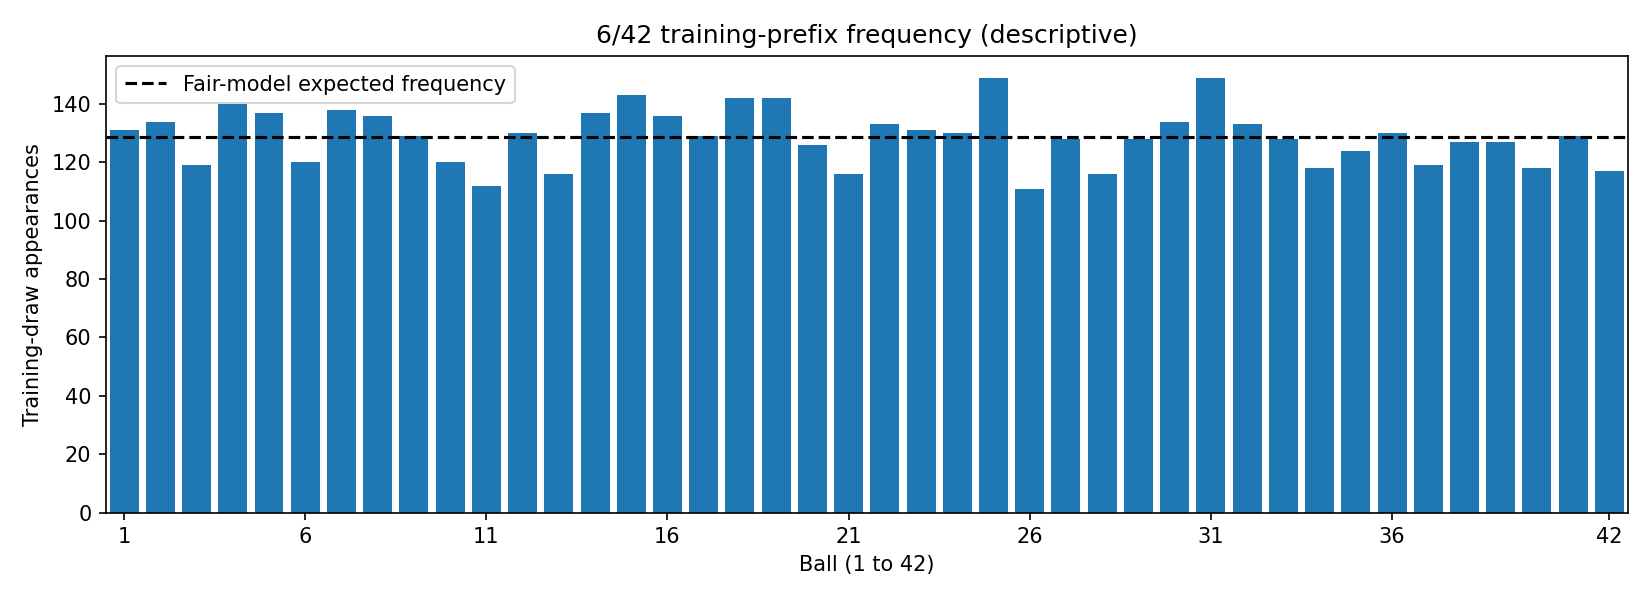

### Pair residual heatmap

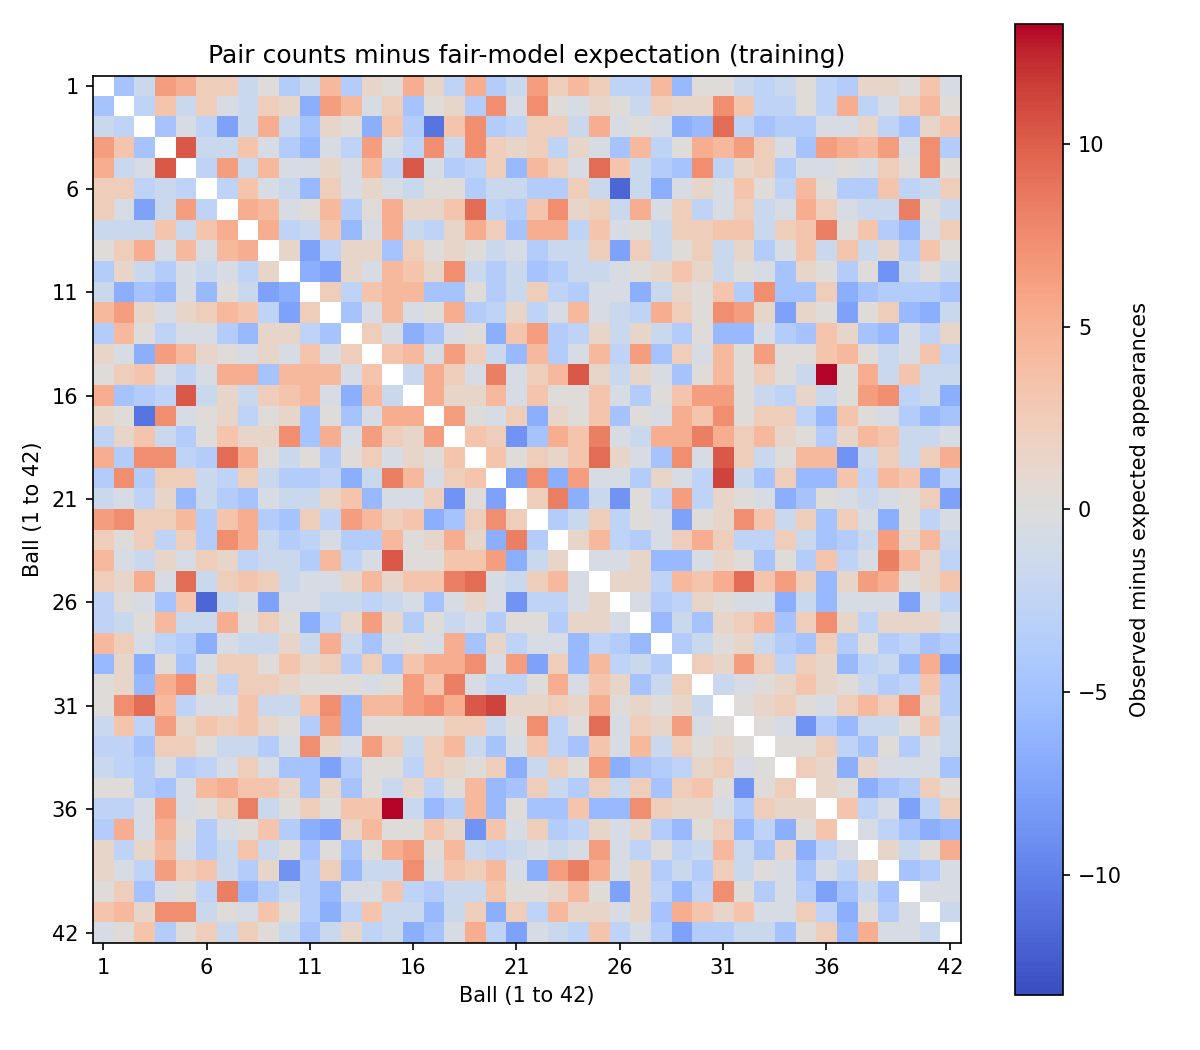

### Cluster ball membership

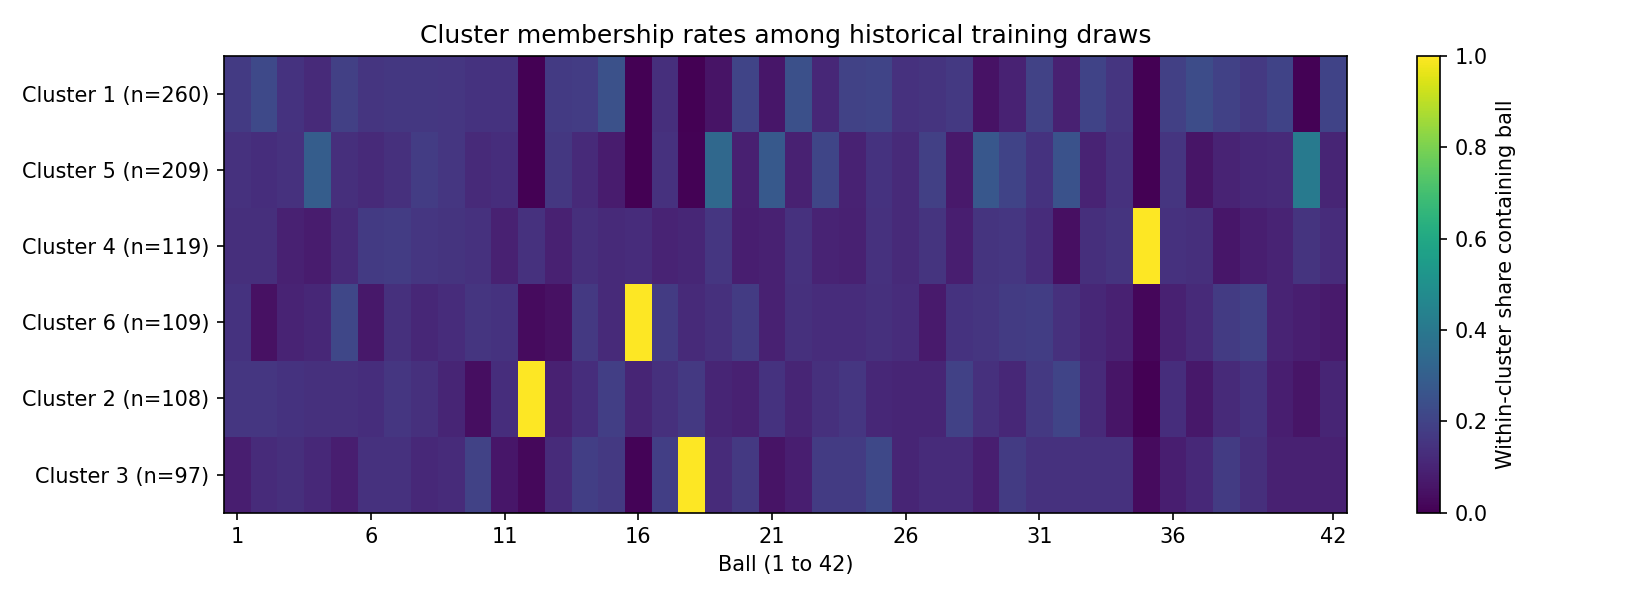

### PCA projection

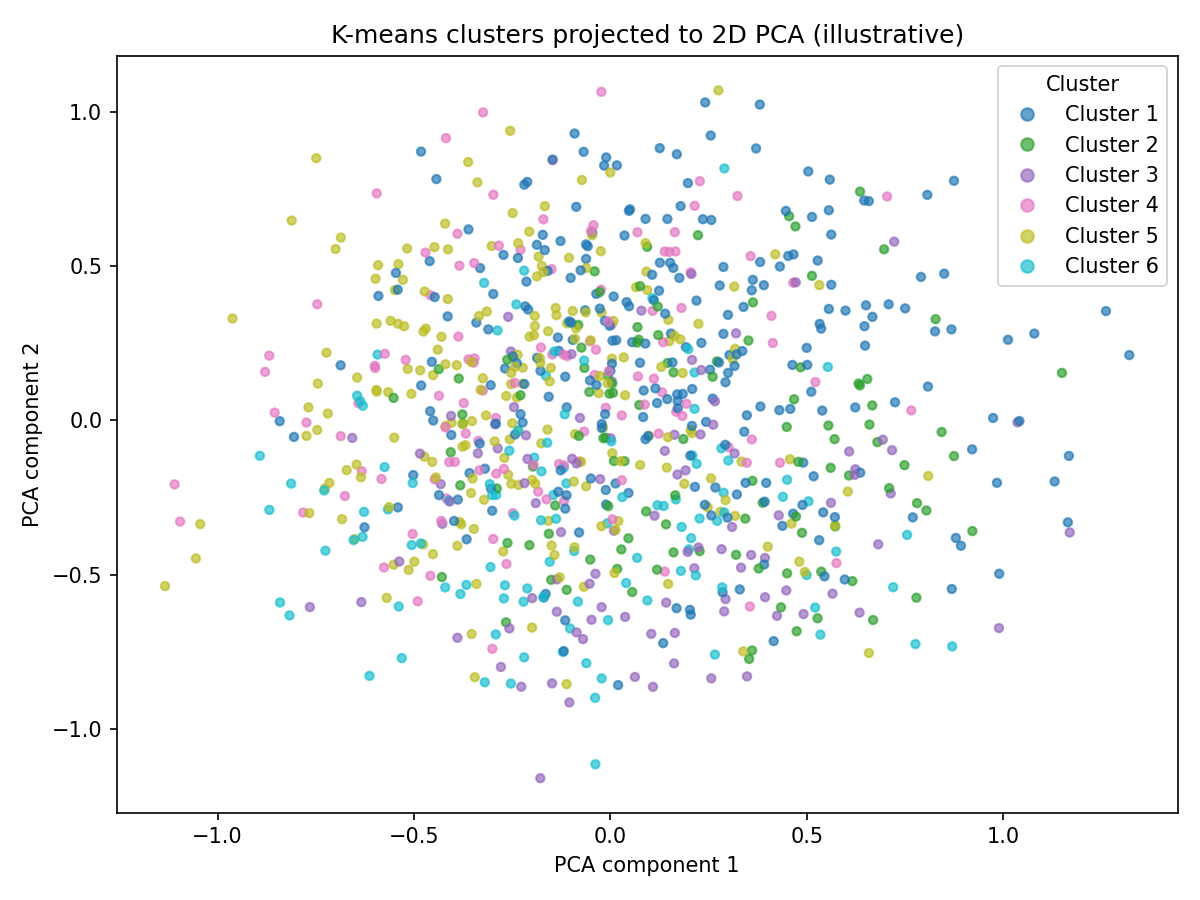

### Elbow plot

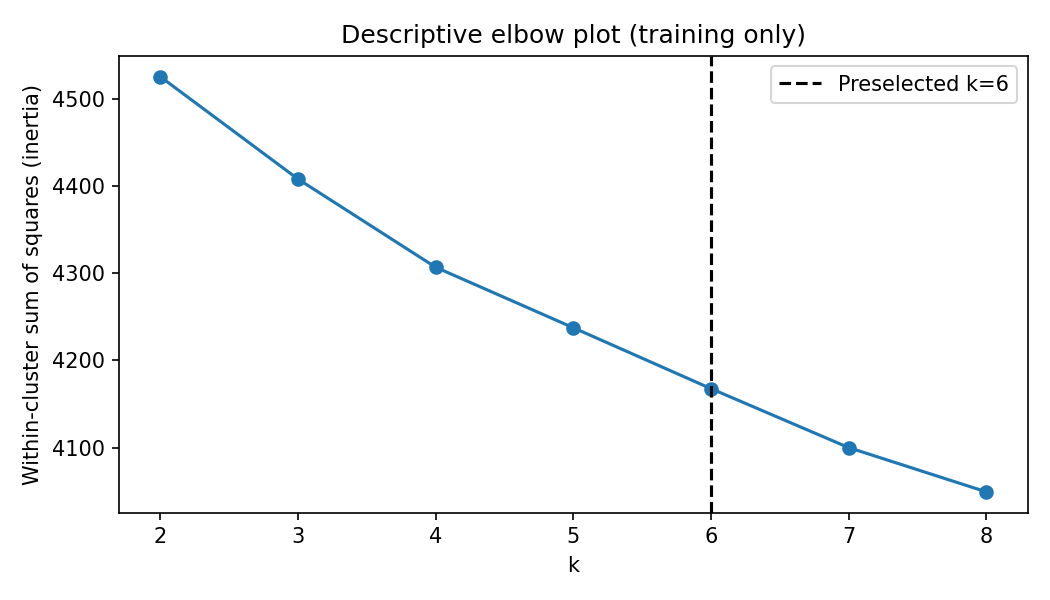

### Fair-null inertia comparison

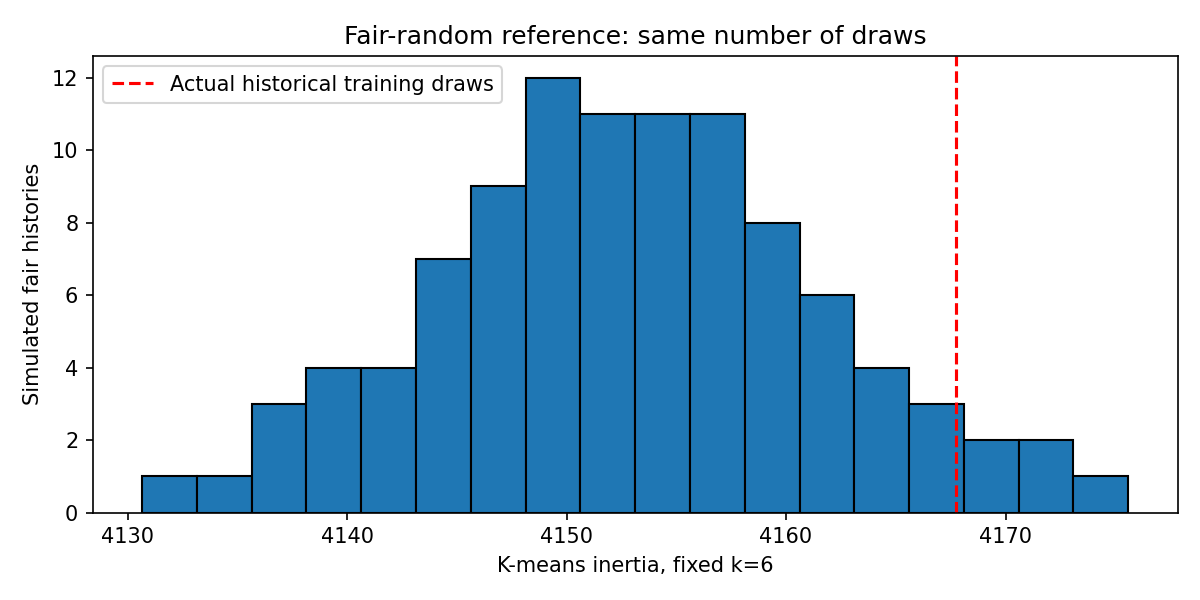

In [3]:
# @title
titles = ['Number frequency', 'Pair residual heatmap', 'Cluster ball membership', 'PCA projection', 'Elbow plot', 'Fair-null inertia comparison']
names = ['01_frequency.png', '02_pair_residuals.png', '03_cluster_profiles.png', '04_cluster_pca.png', '05_elbow.png', '06_null_inertia.png']
for title, name in zip(titles, names):
    display(Markdown('### ' + title))
    display(Image(filename=str(out / name)))


## Evidence summary

The last cell prints the results **actually generated by the Python run**. Simulation p-values refer only to the descriptive lower-inertia diagnostic for fixed k=6. They are not a jackpot probability, an independent prediction test, or evidence of future advantage.


In [4]:
# @title
print((out / 'README.md').read_text(encoding='utf-8'))
print(json.dumps(json.loads((out / 'summary.json').read_text(encoding='utf-8')), indent=2))


# Phase 7: K-means descriptive exploration, Lotto 6/42

**Status: EXPLORATORY ONLY.** Previous STOP_NO_REPRODUCIBLE_PREDICTIVE_SIGNAL unchanged.

Dataset: 902 training draws (2016-08-30 through 2022-11-12). The program reads exactly the first 1003 cleaned records; validation and locked test are not loaded.

Fixed k=6, seed=162, n_init=5, 100 fair synthetic histories. Actual inertia: 4167.725; fair-reference mean: 4152.851; lower-tail simulation p=0.9505.

Interpretation: The clustering inertia was not unusually low relative to fair-draw simulations in this descriptive screen. The observed clusters should not be interpreted as predictive patterns.

Cluster medoids are historical examples, **not forecasts, probabilities, or suggested wagers**. PCA projections, frequency deviations, and co-occurrence differences are descriptive. K-means will form clusters in completely random data as well. The fixed-k inertia comparison is a single exploratory diagnostic and does not correct for trying mu